In [55]:
from scipy.io import loadmat
import pandas as pd
import matplotlib.pyplot as plt

In [101]:
from scipy.io import loadmat
data=loadmat(r'201.mat')
print("نوع داده خوانده شده:", type(data))

print('keys:',data.keys())

نوع داده خوانده شده: <class 'dict'>
keys: dict_keys(['__header__', '__version__', '__globals__', 'X201_DE_time', 'X201_FE_time', 'X201RPM'])


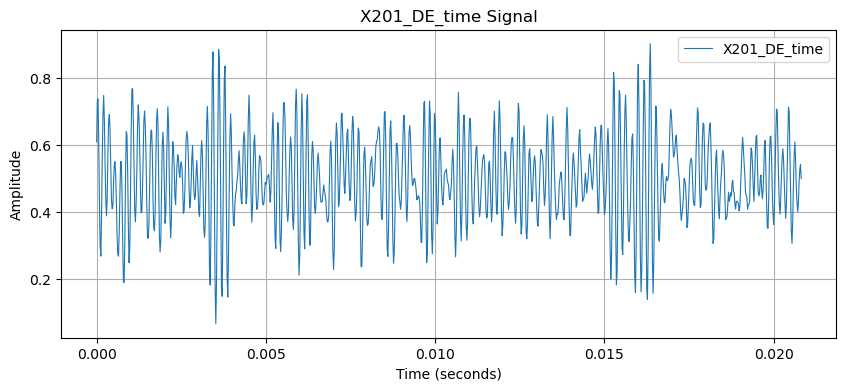

In [99]:
signal = data['X201_DE_time'][:2000:2]
fs = 48000  

#calculating time vector
time = np.arange(len(signal)) / fs  

plt.figure(figsize=(10, 4))
plt.plot(time, signal, label="X201_DE_time", linewidth=0.8)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("X201_DE_time Signal")
plt.legend()
plt.grid()
plt.show()

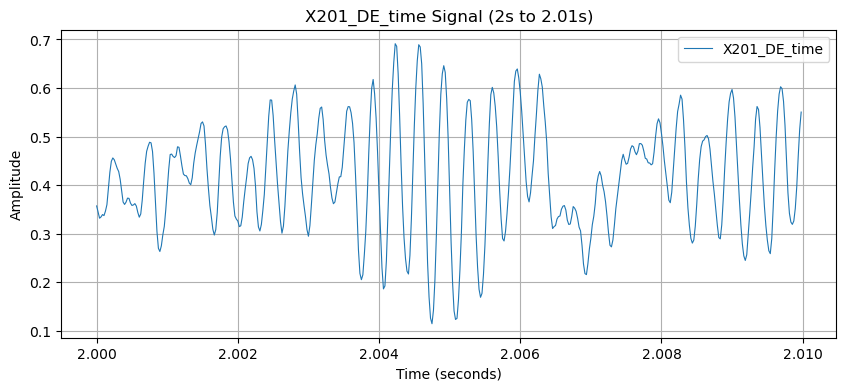

In [77]:
signal = data['X201_DE_time'].flatten()

fs = 48000  

# Calculating time vector
time = np.arange(len(signal)) / fs  

# Define the time range for 2s to 2.01s
start_time = 2.0
end_time = 2.01

# Find the indices corresponding to the selected time range
start_index = np.searchsorted(time, start_time)
end_index = np.searchsorted(time, end_time)

# Extract the corresponding time and signal values
time_selected = time[start_index:end_index]
signal_selected = signal[start_index:end_index]

# Plot the selected time range of the signal
plt.figure(figsize=(10, 4))
plt.plot(time_selected, signal_selected, label="X201_DE_time", linewidth=0.8)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("X201_DE_time Signal (2s to 2.01s)")
plt.legend()
plt.grid()
plt.show()


In [105]:
def compute_fft(signal, sampling_rate):
    N = len(signal)  # تعداد نمونه‌ها
    freq = np.fft.fftfreq(N, d=1/sampling_rate) 
    fft_values = np.fft.fft(signal)  
    
    plt.figure(figsize=(8, 4))
    plt.plot(freq[:N//2], np.abs(fft_values[:N//2])) 
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Amplitude')
    plt.title('Fourier Transform of Signal')
    plt.grid()
    plt.show()

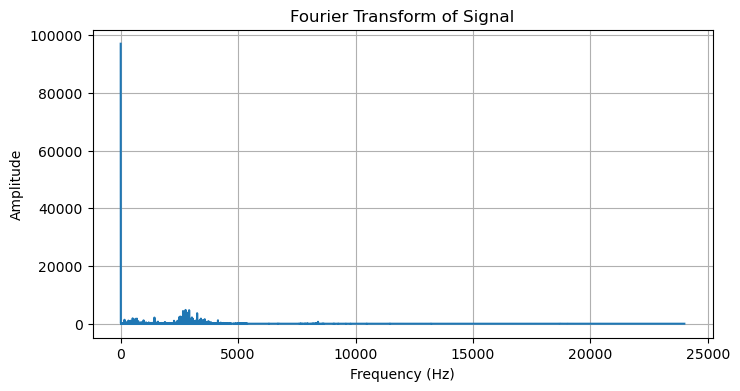

In [109]:
fs = 48000 
signal = data['X201_DE_time'].flatten()
compute_fft(signal, fs)

In [79]:
signal = data['X201_DE_time'].flatten()

# حذف مقدار میانگین سیگنال
signal_detrended = signal - np.mean(signal)

def segment_signal(signal, segment_length=128, overlap=64):
    """
    این تابع سیگنال را به قطعاتی با طول مشخص تقسیم می‌کند و در یک آرایه‌ی numpy ذخیره می‌کند.
    :param signal: سیگنال ورودی
    :param segment_length: طول هر قطعه
    :param overlap: مقدار همپوشانی بین قطعات
    :return: آرایه numpy شامل قطعات سیگنال
    """
    step = segment_length - overlap  # تعداد نمونه‌هایی که در هر مرحله به جلو می‌رویم
    segments = []

    # تقسیم سیگنال به قطعات
    for start in range(0, len(signal) - segment_length + 1, step):
        segment = signal[start:start + segment_length]
        segments.append(segment)

    return np.array(segments)

# تنظیم پارامترهای تقسیم‌بندی
segment_length = 128  # طول هر قطعه
overlap = 64  # مقدار همپوشانی

# تقسیم سیگنال به قطعات
segmented_signal = segment_signal(signal_detrended, segment_length, overlap)

# تبدیل به DataFrame
df_segments = pd.DataFrame(segmented_signal)

# نمایش چند نمونه از داده‌ها
print(df_segments.head())


        0         1         2         3         4         5         6    \
0  0.213103  0.279860  0.334935  0.359551  0.340150  0.280695  0.204133   
1 -0.061852 -0.004900  0.059145  0.115263  0.154482  0.169503  0.153648   
2  0.003236  0.030773  0.065612  0.110465  0.169294  0.221865  0.277148   
3  0.086474  0.018257 -0.029725 -0.031185 -0.001145  0.051009  0.114220   
4  0.243770  0.236885  0.225412  0.202255  0.171172  0.122356  0.075834   

        7         8         9    ...       118       119       120       121  \
0  0.116514  0.031608 -0.038070  ...  0.322835  0.319914  0.286745  0.246065   
1  0.119435  0.060188 -0.015122  ... -0.080627 -0.018877  0.063526  0.139462   
2  0.305937  0.304894  0.289457  ...  0.000107 -0.009698  0.005948  0.033485   
3  0.173884  0.229793  0.282364  ...  0.106292  0.194328  0.262962  0.306354   
4  0.037449  0.016170  0.021594  ... -0.122767 -0.027013  0.072705  0.153857   

        122       123       124       125       126       127  
0  0

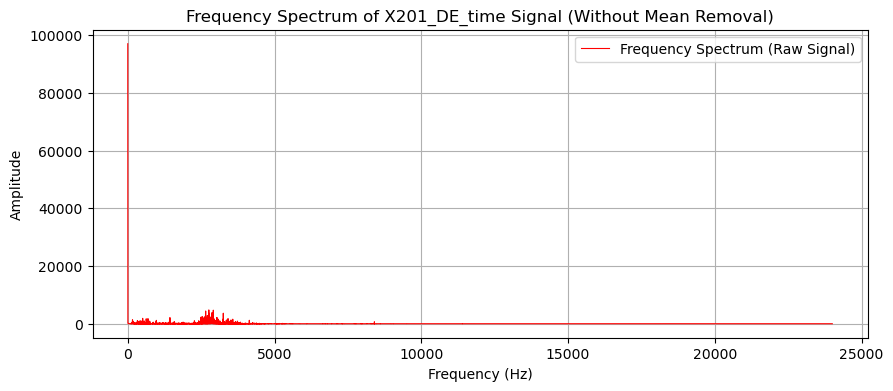

In [93]:
signal = data['X201_DE_time'].flatten()
fs = 48000  

def plot_frequency_spectrum_raw(signal, fs):
    N = len(signal)
    
    fft_values = np.fft.fft(signal)

    freq = np.fft.fftfreq(N, d=1/fs)
    
    positive_freqs = freq[:N//2]
    positive_fft_values = np.abs(fft_values[:N//2])
        plt.figure(figsize=(10, 4))
    plt.plot(positive_freqs, positive_fft_values, label="Frequency Spectrum (Raw Signal)", linewidth=0.8, color='r')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.title("Frequency Spectrum of X201_DE_time Signal (Without Mean Removal)")
    plt.legend()
    plt.grid(True)
    plt.show()
plot_frequency_spectrum_raw(signal, fs)


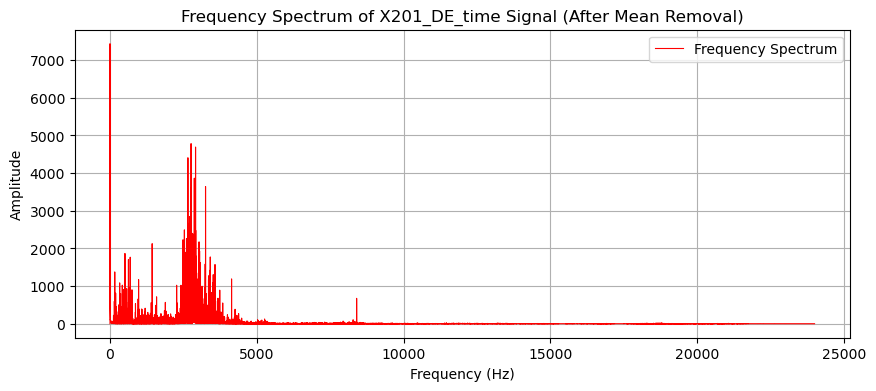

فرکانس غالب سیگنال پس از حذف مقدار میانگین: 0.196 Hz


In [113]:
signal_detrended = signal - np.mean(signal)

def plot_frequency_spectrum(signal, fs):

    N = len(signal)
    fft_values = np.fft.fft(signal)
    freq = np.fft.fftfreq(N, d=1/fs)
    positive_freqs = freq[:N//2]
    positive_fft_values = np.abs(fft_values[:N//2])
    
    plt.figure(figsize=(10, 4))
    plt.plot(positive_freqs, positive_fft_values, label="Frequency Spectrum", linewidth=0.8, color='r')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.title("Frequency Spectrum of X201_DE_time Signal (After Mean Removal)")
    plt.legend()
    plt.grid()
    plt.show()

def find_dominant_frequency(signal, fs):
    fft_values = np.fft.fft(signal)
    freq = np.fft.fftfreq(len(signal), d=1/fs)
    
    positive_freqs = freq[:len(signal)//2]
    positive_fft_values = np.abs(fft_values[:len(signal)//2])

    dominant_frequency = positive_freqs[np.argmax(positive_fft_values)]
    
    return dominant_frequency

plot_frequency_spectrum(signal_detrended, fs)


dominant_freq_corrected = find_dominant_frequency(signal_detrended, fs)
print(f"فرکانس غالب سیگنال پس از حذف مقدار میانگین: {dominant_freq_corrected:.3f} Hz")


In [117]:
signal = data['X201_DE_time'].flatten()
signal_detrended = signal - np.mean(signal)
segment_length = 128 
overlap = 64  

def segment_signal(signal, segment_length=128, overlap=64):

    step = segment_length - overlap 
    segments = []

    for start in range(0, len(signal) - segment_length + 1, step):
        segment = signal[start:start + segment_length]
        segments.append(segment)

    return np.array(segments)

segmented_signal = segment_signal(signal_detrended, segment_length, overlap)

df_segments = pd.DataFrame(segmented_signal)
df_segments

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,0.213103,0.279860,0.334935,0.359551,0.340150,0.280695,0.204133,0.116514,0.031608,-0.038070,...,0.322835,0.319914,0.286745,0.246065,0.199335,0.145303,0.090020,0.036615,0.001359,-0.004274
1,-0.061852,-0.004900,0.059145,0.115263,0.154482,0.169503,0.153648,0.119435,0.060188,-0.015122,...,-0.080627,-0.018877,0.063526,0.139462,0.201421,0.236051,0.241266,0.224786,0.196623,0.150727
2,0.003236,0.030773,0.065612,0.110465,0.169294,0.221865,0.277148,0.305937,0.304894,0.289457,...,0.000107,-0.009698,0.005948,0.033485,0.063526,0.098991,0.140088,0.185149,0.224577,0.244813
3,0.086474,0.018257,-0.029725,-0.031185,-0.001145,0.051009,0.114220,0.173884,0.229793,0.282364,...,0.106292,0.194328,0.262962,0.306354,0.318245,0.296967,0.249611,0.173258,0.065195,-0.053090
4,0.243770,0.236885,0.225412,0.202255,0.171172,0.122356,0.075834,0.037449,0.016170,0.021594,...,-0.122767,-0.027013,0.072705,0.153857,0.224369,0.270681,0.296341,0.285284,0.236051,0.182437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3824,-0.153643,-0.122142,-0.100237,-0.073951,-0.045163,-0.009907,0.015545,0.017631,0.001567,-0.041407,...,-0.113797,-0.115883,-0.111502,-0.092518,-0.090641,-0.086886,-0.076455,-0.062686,-0.046414,-0.048083
3825,-0.024927,0.010329,0.022220,0.031399,0.020134,-0.015748,-0.065607,-0.148844,-0.209760,-0.249188,...,-0.054550,-0.037235,-0.014705,0.002610,0.001776,0.007617,-0.001353,-0.011784,-0.032854,-0.090432
3826,-0.062269,-0.084382,-0.100863,-0.115883,-0.133407,-0.159692,-0.193697,-0.210803,-0.213515,-0.195783,...,-0.039947,-0.002188,0.016379,0.023055,0.031399,0.030356,0.022012,0.004279,-0.027013,-0.056845
3827,-0.140708,-0.185978,-0.212263,-0.212889,-0.204336,-0.171375,-0.134241,-0.087720,-0.032437,0.003862,...,-0.050795,-0.064147,-0.102949,-0.122559,-0.141126,-0.164491,-0.173878,-0.184518,-0.176382,-0.165325


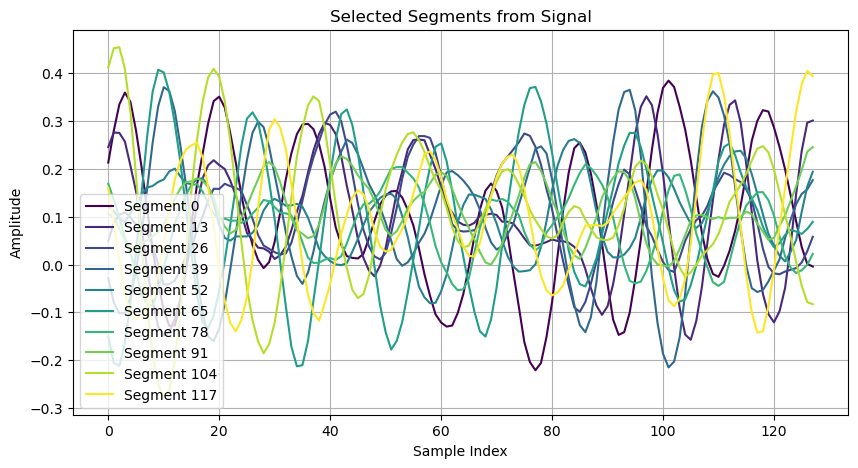

In [85]:
selected_indices = [i for i in range(0, len(df_segments), 13)][:10]
colors = plt.cm.viridis(np.linspace(0, 1, len(selected_indices)))
plt.figure(figsize=(10, 5))

for i, (idx, color) in enumerate(zip(selected_indices, colors)):
    plt.plot(df_segments.iloc[idx], label=f"Segment {idx}", color=color)

plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.title("Selected Segments from Signal")
plt.legend()
plt.grid()
plt.show()

In [119]:
def extract_features(signal):
    mean_value = np.mean(signal)  
    std_value = np.std(signal) 
    rms_value = np.sqrt(np.mean(np.square(signal)))  
    return mean_value, std_value, rms_value

features = []
for i in range(len(df_segments)):
    mean_val, std_val, rms_val = extract_features(df_segments.iloc[i])
    features.append([mean_val, std_val, rms_val])

df_features = pd.DataFrame(features, columns=["Mean", "Std", "RMS"])

csv_filename = "Hoosh1.csv"
df_features.to_csv(csv_filename, index=False)

print(f"ویژگی‌های استخراج‌شده در فایل '{csv_filename}' ذخیره شد.")


ویژگی‌های استخراج‌شده در فایل 'Hoosh1.csv' ذخیره شد.
